In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import json
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [22]:
df=pd.read_csv("calories.csv")

In [23]:
df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [24]:
df.isnull().sum()

User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

In [25]:
df.isna()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
14995,False,False,False,False,False,False,False,False,False
14996,False,False,False,False,False,False,False,False,False
14997,False,False,False,False,False,False,False,False,False
14998,False,False,False,False,False,False,False,False,False


In [26]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
14995    False
14996    False
14997    False
14998    False
14999    False
Length: 15000, dtype: bool

In [27]:
corr = df.drop(columns="Gender").corr()
print(corr["Calories"].sort_values())

User_ID      -0.001661
Height        0.017537
Weight        0.035481
Age           0.154395
Body_Temp     0.824558
Heart_Rate    0.897882
Duration      0.955421
Calories      1.000000
Name: Calories, dtype: float64


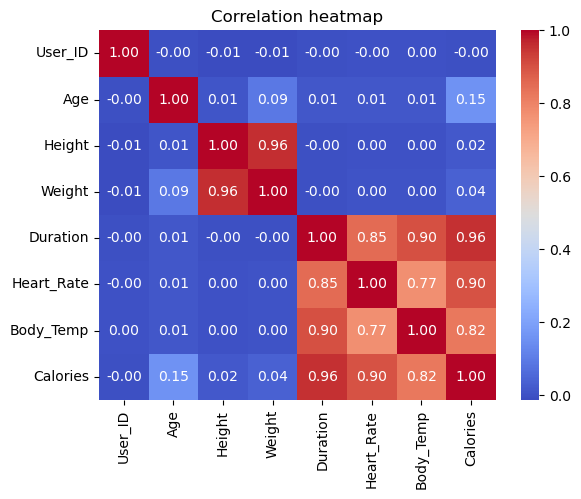

In [28]:
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

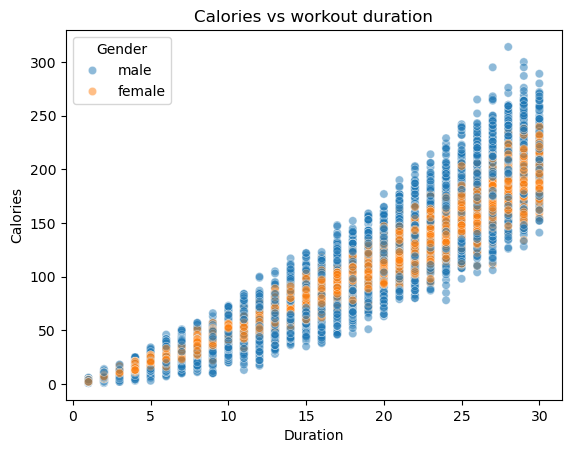

In [29]:
sns.scatterplot(data=df, x="Duration", y="Calories", hue="Gender", alpha=0.5)
plt.title("Calories vs workout duration")
plt.show()

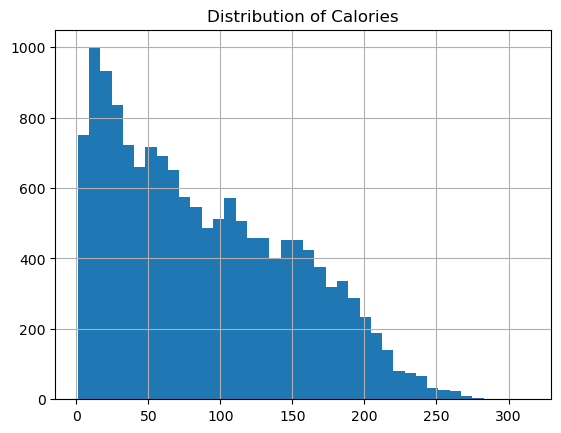

In [30]:
df["Calories"].hist(bins=40)
plt.title("Distribution of Calories")
plt.show()

In [33]:
df["BMI"] = df["Weight"] / (df["Height"] / 100) ** 2

In [34]:
X = df.drop(columns=["Calories", "User_ID"])
y = df["Calories"]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [36]:
num_cols = ["Age", "Height", "Weight", "Duration", "Heart_Rate", "Body_Temp", "BMI"]
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary"), ["Gender"]),
])


In [37]:
candidates = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=4,
        subsample=0.8, random_state=42,
    ),
}


In [38]:
results = {}
best_name, best_rmse, best_pipe = None, np.inf, None

for name, model in candidates.items():
    pipe = Pipeline([("pre", pre), ("model", model)])

    cv_rmse = -cross_val_score(
        pipe, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error"
    ).mean()

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    results[name] = {
        "cv_rmse": round(float(cv_rmse), 3),
        "test_rmse": round(float(np.sqrt(mean_squared_error(y_test, pred))), 3),
        "test_mae": round(float(mean_absolute_error(y_test, pred)), 3),
        "test_r2": round(float(r2_score(y_test, pred)), 4),
    }
    print(name, results[name])

    if cv_rmse < best_rmse:
        best_name, best_rmse, best_pipe = name, cv_rmse, pipe

print("Best model:", best_name)

LinearRegression {'cv_rmse': 10.992, 'test_rmse': 11.22, 'test_mae': 8.195, 'test_r2': 0.9688}
RandomForest {'cv_rmse': 3.169, 'test_rmse': 2.729, 'test_mae': 1.748, 'test_r2': 0.9982}
GradientBoosting {'cv_rmse': 1.74, 'test_rmse': 1.667, 'test_mae': 1.235, 'test_r2': 0.9993}
Best model: GradientBoosting


In [39]:
joblib.dump(best_pipe, "model.joblib")

json.dump(
    {"best": best_name, "results": results},
    open("metrics.json", "w"),
    indent=2
)

print("Model saved successfully!")
print("Best model:", best_name)

Model saved successfully!
Best model: GradientBoosting
